# ``meshlab`` - Tutorial 6

**Axisymmetric aerospike nozzle**


## 1. Import packages
---


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from numpy.typing import ArrayLike

from meshlab.core import Mesh, Curve, Contour, Front, Point, Refinement
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals,
    smooth_normals, advance_front,
)
from meshlab.utils import plot_mesh
from meshlab.export import export_mesh

from functions.discretize_segment import discretize_segment

## 2. Geometry definition
---


Geometry parameters

In [2]:
# Length and height [m]
domain_length = 0.500
domain_height = 0.250
duct_length = 0.005
duct_height = 0.010
spike_length = 0.050
spike_height = 0.030

# Duct exit at x=0; radius measured from y=0.
# Upstream setback and casing radius are specified directly in p3-p5.
p0 = [spike_length, 0.0]
p1 = [domain_length, 0.0]
p2 = [domain_length, domain_height]
p3 = [-0.060, domain_height]
p4 = [-0.060, 0.043]
p5 = [0.0, 0.043]
p6 = [0.0, spike_height + duct_height]
p7 = [-duct_length, spike_height + duct_height]
p8 = [-duct_length, spike_height]
p9 = [0.0, spike_height]

Curve discretization

In [3]:
def create_spike(
        start: ArrayLike,
        end: ArrayLike,
        num_points=101,
        truncation_radius=0.005,
        base_points=11,
        start_angle=20.0,
        end_angle=0.0,
    ) -> np.ndarray:
    """Return a meridional spike contour including its axis endpoint"""

    start = np.asarray(start, dtype=float)
    end = np.asarray(end, dtype=float)
    reverse = start[1] == 0.0
    wall, tip = (end, start) if reverse else (start, end)
    length = tip[0] - wall[0]
    s = np.linspace(0.0, 1.0, num_points)
    slope_start = -np.tan(np.deg2rad(start_angle))
    slope_end = -np.tan(np.deg2rad(end_angle))
    radius = ((2*s**3 - 3*s**2 + 1)*wall[1]
              + (s**3 - 2*s**2 + s)*length*slope_start
              + (-2*s**3 + 3*s**2)*truncation_radius
              + (s**3 - s**2)*length*slope_end)
    points = np.column_stack((wall[0] + s*length, radius))
    points[0] = wall
    points[-1] = [tip[0], truncation_radius]

    if truncation_radius > 0.0:
        base = np.linspace(points[-1], tip, base_points)
        points = np.vstack((points, base[1:]))
    else:
        points[-1] = tip
    
    return points[::-1].copy() if reverse else points


def create_lip(start: ArrayLike, end: ArrayLike, spacing=0.00005) -> np.ndarray:
    """Return a semicircle tangent to the horizontal duct and casing walls"""
    start = np.asarray(start, dtype=float)
    end = np.asarray(end, dtype=float)
    center = (start + end) / 2.0
    radius = (end[1] - start[1]) / 2.0
    count = max(2, int(np.ceil(np.pi * radius / spacing)))
    angle = np.linspace(0.0, np.pi, count + 1)
    points = center + radius * np.column_stack((np.sin(angle), -np.cos(angle)))
    points[0], points[-1] = start, end
    return points


Closed contour

In [4]:
# Clockwise fluid boundary: normals point into the fluid.
channel = Contour(
    name="aerospike",
    curves=[
        Curve("spike",         create_spike(p0, p9)),
        Curve("duct_bottom",   discretize_segment(p9, p8, 0.0002)),
        Curve("inlet",         discretize_segment(p8, p7, 0.0005, 0.0004)),
        Curve("duct_top",      discretize_segment(p7, p6, 0.0001, 0.00002)),
        Curve("outer_lip",     discretize_segment(p6, p5, 0.00002, 0.0001)),
        Curve("outer_casing",  discretize_segment(p5, p4, 0.0001, 0.002)),
        Curve("ambient_inlet", discretize_segment(p4, p3, 0.002, 0.03)),
        Curve("ambient_top",   discretize_segment(p3, p2, 0.03)),
        Curve("outlet",        discretize_segment(p2, p1, 0.03)),
        Curve("axis",          discretize_segment(p1, p0, 0.03, 0.001)),
    ],
)

Boundary-layer parameters

In [5]:
num_layers = 10
height = 2e-5
growth_rate = 1.1
smooth_steps = 3
relaxation = 0.5

## 3. Creating mesh surfaces
---


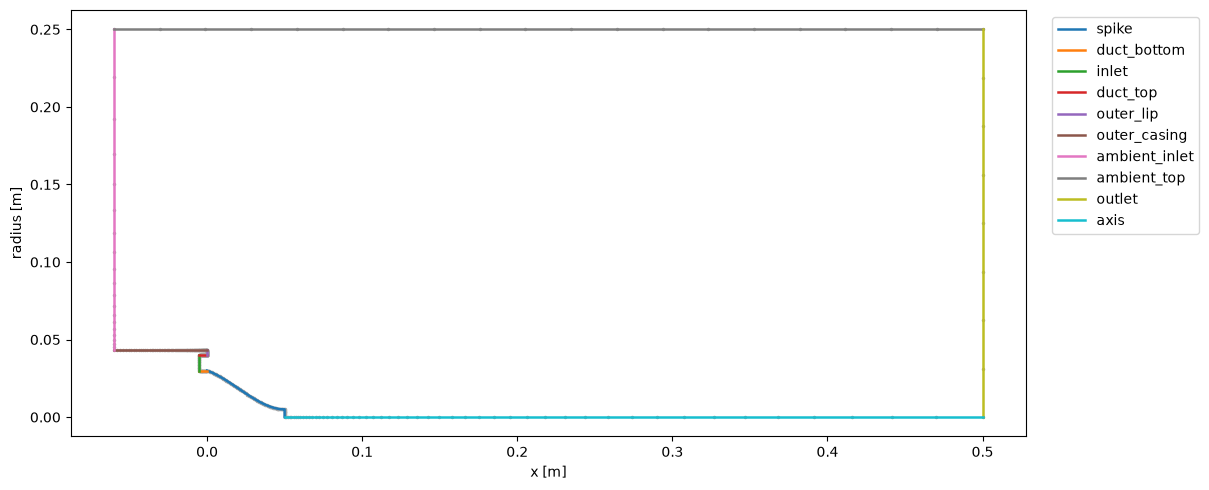

In [6]:
mesh = Mesh(dim=2, vertices_capacity=5000, cells_capacity=5000)
insert_contour(mesh, channel)

figure, ax = plot_mesh(mesh, show=False)
figure.set_size_inches(12, 5)
ax.set_ylabel("radius [m]")
ax.set_xlabel("x [m]")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

## 4. Initialize fronts
---


In [7]:
body_front = Front("body_front", int_dtype=mesh.int_dtype)
outer_front = Front("outer_front", int_dtype=mesh.int_dtype)

initialize_front(mesh, body_front, curves=["spike", "duct_bottom"], guides=["axis", "inlet"])
# One continuous front follows all solid surfaces around the rounded lip.
# initialize_front(
#     mesh, outer_front,
#     curves=["duct_top", "outer_lip", "outer_casing"],
#     guides=["inlet", "ambient_inlet"],
# )

initialize_front(
    mesh, outer_front,
    curves=["duct_top"],
    guides=["inlet"],
)

fronts = [body_front, outer_front]

## 5. Growing boundary layers
---


In [8]:
h = height
for _ in range(num_layers):
    for front in fronts:
        normals = compute_normals(mesh, front, method="bisector")
        for _ in range(smooth_steps):
            normals, _ = smooth_normals(mesh, front, normals, relaxation)
        advance_front(mesh, front, normals, h)
    h *= growth_rate

Near-wall mesh


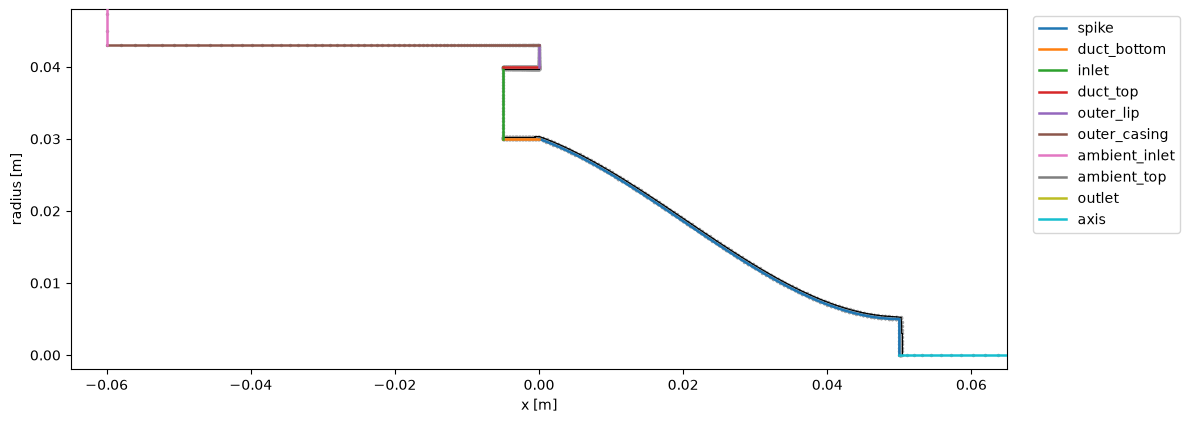

In [9]:
figure, ax = plot_mesh(mesh, show=False)
figure.set_size_inches(12, 6)
ax.set_xlim(p4[0] - 0.005, p0[0] + 0.015)
ax.set_ylim(-0.002, p5[1] + 0.005)
ax.set_xlabel("x [m]")
ax.set_ylabel("radius [m]")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

## 6. Generate and export the axisymmetric mesh
---


In [ ]:
wedge_angle = np.deg2rad(5.0)
show_gmsh = False

refinements = [
    Refinement(
        geometry=Point("lip_resolution", p6),
        size=0.00005,
        distance=0.001,
        transition=0.005,
    ),
]

export_mesh(
    mesh,
    filename="./results/aerospike.msh",
    mode="axisymmetric",
    axis="axis",
    angle=wedge_angle,
    mesh_size=0.02,
    refinements=refinements,
    show=show_gmsh,
)

### OpenFOAM connection
---
- Run in a terminal using a prepared OpenFOAM case:
- Set writePrecision to 16 in system/controlDict before conversion.
- gmshToFoam /path/to/tutorials/results/aerospike.msh
- Set frontAndBack to empty in constant/polyMesh/boundary and the field files.
- checkMesh -allTopology -allGeometry
